In [2]:

def biseccion(f, a, b, TOL=1e-6, N0=100):
    """Devuelve (p, historia), con historia = [(a, b, p) por iteración]."""
    FA = f(a)
    historia = []
    i = 1
    while i <= N0:
        p = a + (b - a) / 2                         # COMPLETE: punto medio estable
        FP = f(p)
        historia.append((a, b, p))                  # COMPLETE: (a, b, p)
        if FP == 0 or (b - a) / 2 < TOL:            # COMPLETE: parada por TOL
            return p, historia
        i = i + 1
        if FA * FP > 0:
            a = p                                   # COMPLETE: mover a y FA
            FA = FP
        else:
            b = p                                   # COMPLETE: mover b
    raise RuntimeError(f"fracasó después de {N0} iteraciones")


In [7]:

def f(x):
    return x**3 + 4*x**2 - 10

p, historia = biseccion(f, 1.0, 2.0, TOL=1e-2)

print(f"Raíz: {p:.6f}")
print(f"Número de iteraciones: {len(historia)}")

print("\nValores explorados:")
for i, (a, b, pi) in enumerate(historia, 1):
    print(f"p{i} = {pi}")

print("\nIntervalo de la iteración 4:")
print(historia[3][0], historia[3][1])


Raíz: 1.367188
Número de iteraciones: 7

Valores explorados:
p1 = 1.5
p2 = 1.25
p3 = 1.375
p4 = 1.3125
p5 = 1.34375
p6 = 1.359375
p7 = 1.3671875

Intervalo de la iteración 4:
1.25 1.375


In [8]:

import numpy as np
import matplotlib.pyplot as plt

g = 9.81
s0, m, k = 300.0, 0.25, 0.1

def s(t):
    return s0 - (m * g / k) * t + (m ** 2 * g / k ** 2) * (1 - np.exp(-k * t / m))

t_star, historia_caida = biseccion(s, 0.0, 20.0, TOL=1e-4)

print(f"Tiempo de caída: {t_star:.6f} segundos")
print(f"Número de iteraciones: {len(historia_caida)}")
print(f"Intervalo de la iteración 3: {historia_caida[2][:2]}")
print(f"Punto medio de la iteración 3: {historia_caida[2][2]}")


Tiempo de caída: 14.725571 segundos
Número de iteraciones: 18
Intervalo de la iteración 3: (10.0, 15.0)
Punto medio de la iteración 3: 12.5


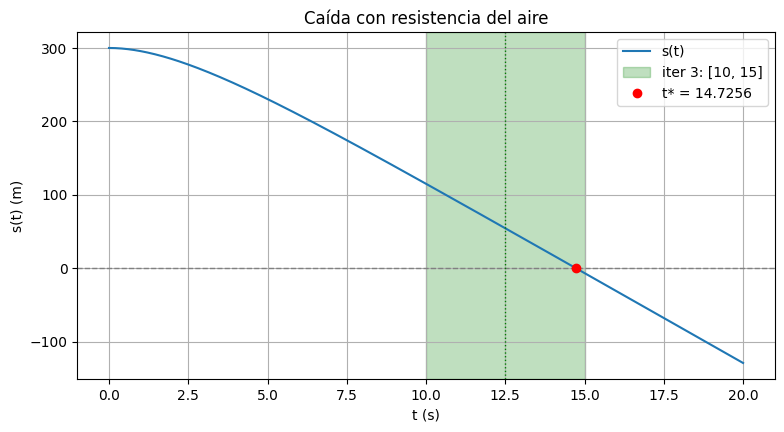

In [9]:

def graficar(t_star, historia, k_iteracion=None, archivo="caida.png"):
    """Dibuja s(t). Si k_iteracion no es None, resalta el intervalo [a, b]
    de esa iteración (1-based) y su punto medio p."""
    t = np.linspace(0, 20, 400)
    plt.figure(figsize=(9, 4.5))
    plt.plot(t, s(t), label="s(t)")
    plt.axhline(0, color="gray", linestyle="--", linewidth=1)
    if k_iteracion is not None:
        a, b, p = historia[k_iteracion - 1]
        plt.axvspan(a, b, color="green", alpha=0.25,
                    label=f"iter {k_iteracion}: [{a:.4g}, {b:.4g}]")
        plt.axvline(p, color="green", linestyle=":", linewidth=1)
    plt.plot(t_star, 0, "ro", label=f"t* = {t_star:.4f}")
    plt.xlabel("t (s)")
    plt.ylabel("s(t) (m)")
    plt.title("Caída con resistencia del aire")
    plt.legend()
    plt.grid(True)
    plt.savefig(archivo, dpi=150)
    plt.show()


graficar(t_star, historia_caida, k_iteracion=3)
